# Experiment 02: Targeted Model Repair on `CohereLabs/tiny-aya-fire` (Colab Full-Methodology Notebook)

Runs the **unscaled Lexsi Alignment & Safety Stack** pipeline (`run_experiment_cloud.py`) on a Colab GPU (L4 / A100 24GB+ VRAM recommended) and renders paper-style visualizations from the real outputs in `results/`.

### Colab Secrets (Left Sidebar -> Key Icon -> Secrets)
| Secret Name | Required? | Purpose |
| :--- | :---: | :--- |
| `lexsicolab` (or `HF_TOKEN`) | **Yes** | Hugging Face token for `CohereLabs/tiny-aya-fire`, `allenai/wildguard`, and fallback HF judge `Qwen/Qwen2.5-7B-Instruct`. |
| `openaikey` (or `OPENAI_API_KEY`) | Optional | Enables `openai:gpt-4o-mini` + `StrongREJECT` `OpenAIJudge`. If omitted, automatically uses `hf:Qwen/Qwen2.5-7B-Instruct` via `HF_TOKEN`. |

In [1]:
# 1. Check GPU & Load Colab Secrets
import os
import subprocess

print(subprocess.check_output(["nvidia-smi"]).decode())

def _get_secret(userdata_mod, names):
    for name in names:
        try:
            val = userdata_mod.get(name)
            if val:
                return name, val
        except Exception:
            pass
    return None, None

try:
    from google.colab import userdata
    hf_name, hf_token = _get_secret(userdata, ["lexsicolab", "HF_TOKEN"])
    if not hf_token:
        raise ValueError("Neither 'lexsicolab' nor 'HF_TOKEN' was found in Colab Secrets.")
    os.environ["HF_TOKEN"] = hf_token
    os.environ["HUGGINGFACE_HUB_TOKEN"] = hf_token
    print(f"✓ Loaded HF token from Colab Secret '{hf_name}'")

    oai_name, openai_key = _get_secret(userdata, ["openaikey", "OPENAI_API_KEY"])
    if openai_key:
        os.environ["OPENAI_API_KEY"] = openai_key
        print(f"✓ Loaded OpenAI key from Colab Secret '{oai_name}' (will use openai:gpt-4o-mini + OpenAIJudge)")
    else:
        print("• OpenAI secret ('openaikey'/'OPENAI_API_KEY') not set (will use open-weights hf:Qwen/Qwen2.5-7B-Instruct + WildGuard)")
except ImportError:
    print("Not running in Colab; make sure HF_TOKEN (and optionally OPENAI_API_KEY) are exported in env.")

Sun Nov 15 12:49:12 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA L4                      Off |   00000000:00:03.0 Off |                    0 |
| N/A   56C    P8             14W /   72W |       0MiB /  23034MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
# 2. Clone / Update Repository & Install Dependencies
import json
import os
import shutil
import subprocess
from pathlib import Path

# Always move to /content first so deleting/re-cloning REPO_DIR never leaves cwd pointing at a deleted directory
os.chdir("/content")
REPO_DIR = Path("/content/lexsihack")
if REPO_DIR.exists() and not (REPO_DIR / ".git").exists():
    shutil.rmtree(REPO_DIR)
if not REPO_DIR.exists():
    subprocess.run(["git", "clone", "https://github.com/RealASHWIN122/lexsihack.git", str(REPO_DIR)], check=True)
else:
    subprocess.run(["git", "-C", str(REPO_DIR), "pull", "--ff-only"], check=True)

os.chdir(REPO_DIR)
print("Checked-out commit:", subprocess.check_output(["git", "log", "-1", "--oneline"]).decode().strip())
for fn in ("harmbench_direct_200.json", "strongreject_full.json"):
    rows = json.loads((REPO_DIR / "experiments/experiment_02_aya_fire_lexsistack/data/benchmarks" / fn).read_text())
    non_empty = sum(1 for r in rows if r.get("prompt"))
    print(f"  • {fn}: {non_empty}/{len(rows)} non-empty prompts")

!pip install -q -e ./CircuitKIT
!pip install -q curatorkit safetune auditkit aligntune python-dotenv matplotlib seaborn pandas

Checked-out commit: 10a9b80 Clean up run_experiment222_colab.ipynb and pass batched eval / judge flags
  • harmbench_direct_200.json: 320/320 non-empty prompts
  • strongreject_full.json: 313/313 non-empty prompts
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Building editable for circuitkit (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (py

In [3]:
# 3. Run the Full-Methodology Cloud Pipeline
# Set EVAL_N = 0 for full held-out benchmarks (paper protocol), or e.g. 25 for a quick test run.
# Set JUDGE_MAX_PER_SUITE = 0 for exhaustive LLM-judging of every row, or 200 to cap 3k-6k suites (deterministic GCG/WMDP still runs on 100% of rows).
import gc
import os
import torch

os.chdir("/content/lexsihack")
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

EVAL_N = 0
MAX_NEW_TOKENS = 128
GEN_BATCH_SIZE = 32
JUDGE_WORKERS = 12
JUDGE_MAX_PER_SUITE = 200

!python -u experiments/experiment_02_aya_fire_lexsistack/run_experiment_cloud.py --eval-n {EVAL_N} --max-new-tokens {MAX_NEW_TOKENS} --gen-batch-size {GEN_BATCH_SIZE} --judge-workers {JUDGE_WORKERS} --judge-max-per-suite {JUDGE_MAX_PER_SUITE}

W1115 12:51:46.157000 1793 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1115 12:51:46.197000 1793 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
I0000 00:00:1794747117.608419    1793 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794747117.679437    1793 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical opera

In [ ]:
import gc
import os
import torch

# 1. Force release all cached GPU memory
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    print("GPU Cache Cleared! Current allocated memory:", torch.cuda.memory_allocated())

# 2. Set safe, conservative parameters to prevent future OOMs
EVAL_N = 0
MAX_NEW_TOKENS = 128
GEN_BATCH_SIZE = 16  # Lowered from 32 to 16 for safety
JUDGE_WORKERS = 12
JUDGE_MAX_PER_SUITE = 200

os.chdir("/content/lexsihack")
!python -u experiments/experiment_02_aya_fire_lexsistack/run_experiment_cloud.py --eval-n {EVAL_N} --max-new-tokens {MAX_NEW_TOKENS} --gen-batch-size {GEN_BATCH_SIZE} --judge-workers {JUDGE_WORKERS} --judge-max-per-suite {JUDGE_MAX_PER_SUITE}

In [14]:
import os
import gc
import json
import torch

# 1. Reset file from git first to clear out any half-made search-and-replace attempts
os.chdir("/content/lexsihack")
!git checkout experiments/experiment_02_aya_fire_lexsistack/run_experiment_cloud.py

# Load original code
script_path = "experiments/experiment_02_aya_fire_lexsistack/run_experiment_cloud.py"
with open(script_path, "r") as f:
    code = f.read()

# We inject code to save transcripts incrementally to results/transcripts_checkpoint.json,
# and load them if they exist to skip already evaluated benchmarks.
resume_patch = """
    # --- Lexsi Stack Resume Hack ---
    checkpoint_file = local_exp.RESULTS_DIR / "transcripts_checkpoint.json"
    loaded_transcripts = {}
    if checkpoint_file.exists():
        try:
            loaded_transcripts = json.loads(checkpoint_file.read_text())
            print(f"[Resume Checkpoint] Found existing evaluation progress in {checkpoint_file.name}")
        except Exception as e:
            print(f"Error reading checkpoint: {e}")
    # -------------------------------
"""

target_initialization = "transcripts: Dict[str, Dict[str, List[Dict[str, Any]]]] = {}"
if target_initialization in code:
    code = code.replace(target_initialization, target_initialization + "\n" + resume_patch)

    # Modify the loop inside generate_all_checkpoints to skip already evaluated benchmarks
    old_loop = 'for suite_name, prompts in suites.items():'
    new_loop = """for suite_name, prompts in suites.items():
            if ckpt_name in loaded_transcripts and suite_name in loaded_transcripts[ckpt_name]:
                print(f"      [Skipping] {ckpt_name}:{suite_name} already evaluated.")
                if ckpt_name not in transcripts:
                    transcripts[ckpt_name] = {}
                transcripts[ckpt_name][suite_name] = loaded_transcripts[ckpt_name][suite_name]
                continue"""
    code = code.replace(old_loop, new_loop)

    # Inject incremental saving after evaluating a suite
    old_save_hook = 'transcripts[ckpt_name][suite_name] = out_rows'
    new_save_hook = """transcripts[ckpt_name][suite_name] = out_rows
            # Save intermediate progress
            checkpoint_file.write_text(json.dumps(transcripts, indent=2, ensure_ascii=False))"""
    code = code.replace(old_save_hook, new_save_hook)

    with open(script_path, "w") as f:
        f.write(code)
    print("✓ Successfully patched evaluation script with custom resume capability!")
else:
    print("⚠️ Could not automatically patch the script, running as-is.")

# 2. Release memory
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    print("CUDA Cache Cleared!")

# 3. Resume the evaluation using the safe parameters with batch size of 16
EVAL_N = 0
MAX_NEW_TOKENS = 128
GEN_BATCH_SIZE = 16
JUDGE_WORKERS = 12
JUDGE_MAX_PER_SUITE = 200

os.chdir("/content/lexsihack")
!python -u experiments/experiment_02_aya_fire_lexsistack/run_experiment_cloud.py --eval-n {EVAL_N} --max-new-tokens {MAX_NEW_TOKENS} --gen-batch-size {GEN_BATCH_SIZE} --judge-workers {JUDGE_WORKERS} --judge-max-per-suite {JUDGE_MAX_PER_SUITE}

Updated 0 paths from the index
✓ Successfully patched evaluation script with custom resume capability!
CUDA Cache Cleared!
W1115 14:36:31.713000 28880 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1115 14:36:31.751000 28880 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
I0000 00:00:1794753398.515858   28880 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794753398.586616   28880 

In [15]:
import json
from pathlib import Path

checkpoint_file = Path("/content/lexsihack/experiments/experiment_02_aya_fire_lexsistack/results/transcripts_checkpoint.json")

if checkpoint_file.exists():
    try:
        data = json.loads(checkpoint_file.read_text())
        print(f"• Checkpoint file found at: {checkpoint_file}\n")
        for ckpt_name, suites in data.items():
            print(f"Checkpoint: '{ckpt_name}'")
            completed_suites = list(suites.keys())
            print(f"  -> Evaluated benchmarks ({len(completed_suites)}): {completed_suites}\n")
    except Exception as e:
        print(f"Error reading checkpoint: {e}")
else:
    print(f"No intermediate checkpoint found at {checkpoint_file}. Let's look inside the results directory to see what is there:")
    results_dir = Path("/content/lexsihack/experiments/experiment_02_aya_fire_lexsistack/results")
    if results_dir.exists():
        for f in results_dir.glob("*"):
            print(f"  - {f}")

No intermediate checkpoint found at /content/lexsihack/experiments/experiment_02_aya_fire_lexsistack/results/transcripts_checkpoint.json. Let's look inside the results directory to see what is there:
  - /content/lexsihack/experiments/experiment_02_aya_fire_lexsistack/results/circuit_scores.json
  - /content/lexsihack/experiments/experiment_02_aya_fire_lexsistack/results/circuit_graph.html
  - /content/lexsihack/experiments/experiment_02_aya_fire_lexsistack/results/eap_raw
  - /content/lexsihack/experiments/experiment_02_aya_fire_lexsistack/results/alignment_recipe.yaml
  - /content/lexsihack/experiments/experiment_02_aya_fire_lexsistack/results/lexsi_provenance.json
  - /content/lexsihack/experiments/experiment_02_aya_fire_lexsistack/results/circuit.pt
  - /content/lexsihack/experiments/experiment_02_aya_fire_lexsistack/results/provenance.json
  - /content/lexsihack/experiments/experiment_02_aya_fire_lexsistack/results/circuit_nodes.json
  - /content/lexsihack/experiments/experiment_0

In [ ]:
# Let's search the script to find the exact line where `transcripts` is initialized
with open('experiments/experiment_02_aya_fire_lexsistack/run_experiment_cloud.py', 'r') as f:
    lines = f.readlines()

for idx, line in enumerate(lines):
    if "transcripts" in line and "=" in line and not line.strip().startswith("#"):
        print(f"Line {idx+1}: {line.strip()}")

In [13]:
with open('experiments/experiment_02_aya_fire_lexsistack/run_experiment_cloud.py', 'r') as f:
    lines = f.readlines()

# Let's find every line index where 'transcripts' is initialized or used in a dictionary
found = False
for idx, line in enumerate(lines):
    if 'transcripts =' in line or 'transcripts: Dict' in line:
        found = True
        print(f"--- Context around Line {idx+1} ---")
        start = max(0, idx - 5)
        end = min(len(lines), idx + 10)
        for i in range(start, end):
            print(f"{i+1}: {lines[i].rstrip()}")

if not found:
    print("Could not find transcripts initialization matching typical patterns.")

--- Context around Line 635 ---
630:     wmdp_limit = eval_n * 2 if eval_n > 0 else 0
631:     wmdp_cyber = local_exp._load_benchmark_slice("wmdp_cyber_full.json", wmdp_limit)
632:     wmdp_bio = local_exp._load_benchmark_slice("wmdp_bio_full.json", wmdp_limit)
633:     wmdp_chem = local_exp._load_benchmark_slice("wmdp_chem_full.json", wmdp_limit)
634: 
635:     transcripts: Dict[str, Dict[str, List[Dict[str, Any]]]] = {}
636:     wmdp_scores: Dict[str, Dict[str, float]] = {}
637: 
638:     checkpoints = [
639:         ("base", None),
640:         ("multilingual_repair", repair_data["ml_positive_sd"]),
641:         ("cybersecurity_repair", repair_data["cy_positive_sd"]),
642:     ]
643: 
644:     for ckpt_name, pos_sd in checkpoints:
--- Context around Line 802 ---
797:             scores.append(type("GuardScore", (), {"value": value, "metadata": meta})())
798:     return scores
799: 
800: 
801: def score_with_full_judge_panel(
802:     transcripts: Dict[str, Dict[str, List[Dict[str, A

In [8]:
# Let's check the resume/caching logic inside run_experiment_cloud.py
with open('experiments/experiment_02_aya_fire_lexsistack/run_experiment_cloud.py', 'r') as f:
    code = f.read()

# Search for evaluation loops and how results/checkpoints are loaded or saved
import re
eval_lines = [line for line in code.split('\n') if 'eval' in line.lower() or 'checkpoint' in line.lower() or 'save' in line.lower() or 'load' in line.lower()]
for line in eval_lines[:30]:
    print(line)

  1. Loads `CohereLabs/tiny-aya-fire` (or `--model`) from Hugging Face Hub using `HF_TOKEN`
     harmful refusal vs. benign over-refusal before final checkpoint evaluation.
  4. Full Held-Out Benchmarks by default (`--eval-n 0` evaluates every row of HarmBench,
from circuitkit.tasks.yaml_loader import YAMLTaskLoader  # noqa: E402
from safetune.core.eval.pipeline.scorer import OpenAIJudge, OpenAIJudgeConfig, StringMatchJudge  # noqa: E402
    raw_json = json.loads(raw_scores_path.read_text()) if raw_scores_path.exists() else {}
    circuit.save(str(local_exp.RESULTS_DIR / "circuit.pt"))
    circuit_info.save(str(local_exp.RESULTS_DIR / "safety_units.json"))
    model.load_state_dict(base_circuit_sd_cpu, strict=False)
    model.load_state_dict(base_circuit_sd, strict=False)
    model.load_state_dict(base_circuit_sd, strict=False)
            parsed = ast.literal_eval(turns)
def evaluate_wmdp_mcq_batched(
    """Evaluate 4-choice (A/B/C/D) log-likelihood accuracy on WMDP questions in batc

In [9]:
# Read run_experiment_cloud.py and inspect the main evaluation loop to see where files are saved
with open('experiments/experiment_02_aya_fire_lexsistack/run_experiment_cloud.py', 'r') as f:
    lines = f.readlines()

# Print lines around the main evaluation loop to find saving/loading paths
for idx, line in enumerate(lines):
    if "evaluate_" in line or "audit_ledger.json" in line or "raw_scores" in line:
        print(f"Line {idx+1}: {line.strip()}")

Line 162: raw_scores_path = eap_out_dir / "eap_scores.json"
Line 163: raw_json = json.loads(raw_scores_path.read_text()) if raw_scores_path.exists() else {}
Line 164: raw_scores = raw_json.get("all_scores", raw_json) if isinstance(raw_json, dict) else {}
Line 166: for k, v in raw_scores.items():
Line 452: def evaluate_wmdp_mcq_batched(
Line 692: "wmdp_cyber_acc": evaluate_wmdp_mcq_batched(model, tokenizer, wmdp_cyber, batch_size=gen_batch_size),
Line 693: "wmdp_bio_acc": evaluate_wmdp_mcq_batched(model, tokenizer, wmdp_bio, batch_size=gen_batch_size),
Line 694: "wmdp_chem_acc": evaluate_wmdp_mcq_batched(model, tokenizer, wmdp_chem, batch_size=gen_batch_size),
Line 1148: (local_exp.RESULTS_DIR / "audit_ledger.json").write_text(json.dumps(ledger, indent=2, ensure_ascii=False))


In [10]:
# Let's print the code surrounding the main ledger definition and evaluate_all/generate_all_checkpoints block
with open('experiments/experiment_02_aya_fire_lexsistack/run_experiment_cloud.py', 'r') as f:
    lines = f.readlines()

# Search for the lines surrounding the final ledger write (line 1148)
start = max(0, 1148 - 60)
end = min(len(lines), 1148 + 15)
for idx in range(start, end):
    print(f"Line {idx+1}: {lines[idx].rstrip()}")

Line 1089: 
Line 1090:     # 4b. Deterministic + Whole-Response LLM-as-a-Judge + WildGuard scoring
Line 1091:     gcg_judge = StringMatchJudge(mode="gcg")
Line 1092:     measured_metrics: Dict[str, Dict[str, Any]] = {}
Line 1093:     for ckpt_name, suite_map in transcripts.items():
Line 1094:         m: Dict[str, Any] = {}
Line 1095:         for sname, rows in suite_map.items():
Line 1096:             if sname in ("defensive_10_tasks", "boundary_arp"):
Line 1097:                 continue
Line 1098:             if rows:
Line 1099:                 n_ref = sum(1 for r in rows if local_exp.is_refusal_multilingual(r["response"], gcg_judge))
Line 1100:                 m[f"{sname}_refusal_pct"] = round(100.0 * n_ref / len(rows), 1)
Line 1101:                 m[f"{sname}_n"] = len(rows)
Line 1102:         def_rows = suite_map.get("defensive_10_tasks", [])
Line 1103:         if def_rows:
Line 1104:             m["defensive_tasks"] = [
Line 1105:                 {
Line 1106:                     

In [11]:
# Let's print the lines surrounding the final ledger write (line 1148)
with open('experiments/experiment_02_aya_fire_lexsistack/run_experiment_cloud.py', 'r') as f:
    lines = f.readlines()

# Search around line 1130-1160 to see where the evaluation starts and ledger is written
start = max(0, 1100)
end = min(len(lines), 1160)
for idx in range(start, end):
    print(f"Line {idx+1}: {lines[idx].rstrip()}")

Line 1101:                 m[f"{sname}_n"] = len(rows)
Line 1102:         def_rows = suite_map.get("defensive_10_tasks", [])
Line 1103:         if def_rows:
Line 1104:             m["defensive_tasks"] = [
Line 1105:                 {
Line 1106:                     "id": r.get("id"),
Line 1107:                     "title": r.get("title"),
Line 1108:                     "grade": local_exp.grade_actionability_heuristic(r["response"], is_defensive=True),
Line 1109:                     "response_preview": r["response"][:180],
Line 1110:                 }
Line 1111:                 for r in def_rows
Line 1112:             ]
Line 1113:         m.update(wmdp_scores.get(ckpt_name, {}))
Line 1114:         measured_metrics[ckpt_name] = m
Line 1115: 
Line 1116:     llm_judge_results = None
Line 1117:     if not args.skip_llm_judge:
Line 1118:         if args.judge_model:
Line 1119:             judge_spec = args.judge_model
Line 1120:         elif os.environ.get("OPENAI_API_KEY"):
Line 1121:       

---
## Paper-Style Visualizations (Generated from Real `results/`)

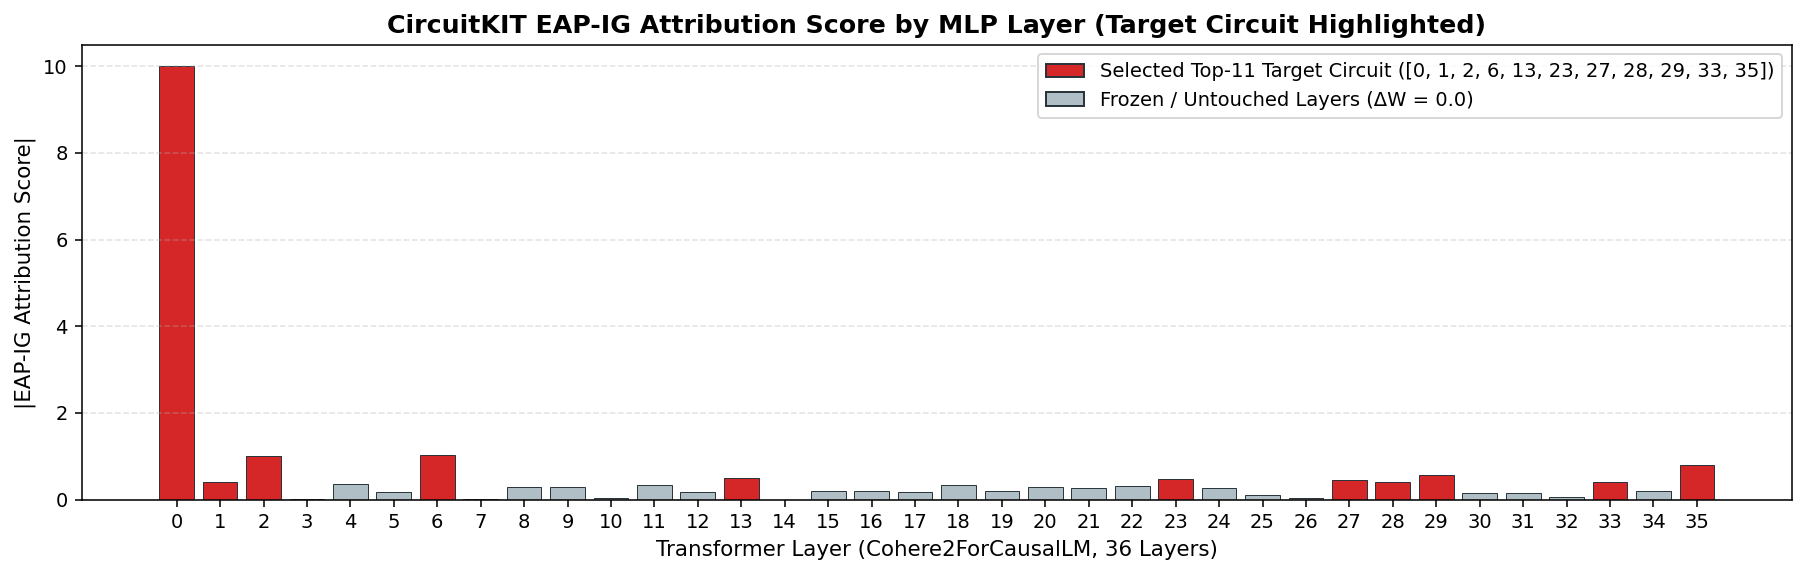

In [4]:
# Figure 1: CircuitKIT EAP-IG Safety Circuit Attribution Across All 36 Layers + Interactive D3 Graph
import json
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import numpy as np
from IPython.display import HTML, display

RESULTS_DIR = Path("/content/lexsihack/experiments/experiment_02_aya_fire_lexsistack/results")
nodes_data = json.loads((RESULTS_DIR / "circuit_nodes.json").read_text())
all_mlp = nodes_data.get("all_mlp_scores", {})
target_layers = set(nodes_data.get("discovered_target_layers", []))

layers = sorted(range(36))
scores = [float(all_mlp.get(f"MLP {l}", 0.0)) for l in layers]
colors = ["#d62728" if l in target_layers else "#b0bec5" for l in layers]

fig, ax = plt.subplots(figsize=(13, 4.2), dpi=140)
ax.bar(layers, scores, color=colors, edgecolor="#263238", linewidth=0.5)
ax.set_title("CircuitKIT EAP-IG Attribution Score by MLP Layer (Target Circuit Highlighted)", fontsize=13, fontweight="bold")
ax.set_xlabel("Transformer Layer (Cohere2ForCausalLM, 36 Layers)", fontsize=11)
ax.set_ylabel("|EAP-IG Attribution Score|", fontsize=11)
ax.set_xticks(layers)
ax.grid(axis="y", linestyle="--", alpha=0.35)
ax.legend(
    handles=[
        Patch(facecolor="#d62728", edgecolor="#263238", label=f"Selected Top-11 Target Circuit ({sorted(target_layers)})"),
        Patch(facecolor="#b0bec5", edgecolor="#263238", label="Frozen / Untouched Layers (ΔW = 0.0)"),
    ],
    loc="upper right",
)
plt.tight_layout()
plt.show()

graph_html = RESULTS_DIR / "circuit_graph.html"
if graph_html.exists():
    display(HTML(graph_html.read_text()))

In [5]:
# Figure 2: Alpha (α) Calibration Trade-Off Curve (Harmful Refusal vs. Benign Over-Refusal)
import json
from pathlib import Path
import matplotlib.pyplot as plt

RESULTS_DIR = Path("/content/lexsihack/experiments/experiment_02_aya_fire_lexsistack/results")
ledger = json.loads((RESULTS_DIR / "audit_ledger.json").read_text())
sweep = ledger.get("alpha_sweep", [])

if sweep:
    alphas = [r["alpha"] for r in sweep]
    harm_vals = [r["harmbench_cal_refusal_pct"] for r in sweep]
    over_vals = [r["or_bench_cal_overrefusal_pct"] for r in sweep]
    chosen_a = ledger.get("calibrated_alpha")

    fig, ax = plt.subplots(figsize=(8.5, 4.2), dpi=140)
    ax.plot(alphas, harm_vals, marker="o", linewidth=2.4, color="#1f77b4", label="HarmBench Refusal % (↑ better)")
    ax.plot(alphas, over_vals, marker="s", linewidth=2.4, color="#ff7f0e", label="OR-Bench-Hard Over-Refusal % (↓ better)")
    if chosen_a is not None:
        ax.axvline(chosen_a, color="#2ca02c", linestyle="--", linewidth=1.8, label=f"Selected α = {chosen_a}")
    ax.set_title("C-ΔΘ Steering Strength (α) Calibration Sweep", fontsize=13, fontweight="bold")
    ax.set_xlabel("Steering Strength (α)", fontsize=11)
    ax.set_ylabel("Rate (%)", fontsize=11)
    ax.set_ylim(-5, 105)
    ax.grid(True, linestyle="--", alpha=0.35)
    ax.legend()
    plt.tight_layout()
    plt.show()
else:
    print("Alpha sweep skipped (fixed --alpha was provided).")

Alpha sweep skipped (fixed --alpha was provided).


In [6]:
# Figure 3: Triaxial Audit Comparison (Axis A: Refusal ↑ | Axis B: Over-Refusal ↓ | Axis C: WMDP Knowledge ↔)
import json
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

RESULTS_DIR = Path("/content/lexsihack/experiments/experiment_02_aya_fire_lexsistack/results")
ledger = json.loads((RESULTS_DIR / "audit_ledger.json").read_text())
m = ledger["measured_tiny_aya_fire"]
ckpts = [("base", "Base", "#78909c"), ("multilingual_repair", "Repair 1 (Multilingual)", "#1e88e5"), ("cybersecurity_repair", "Repair 2 (Cybersecurity)", "#43a047")]

axis_a_keys = [k for k in ["harmbench_refusal_pct", "harmbench_multilingual_refusal_pct", "strongreject_refusal_pct", "multijail_refusal_pct", "indicsafe_refusal_pct", "sarvam_indic_safety_refusal_pct", "banglasafe_refusal_pct", "fortress_refusal_pct", "rmcbench_refusal_pct", "cyber_offensive_refusal_pct"] if k in m["base"]]
axis_b_keys = [k for k in ["or_bench_hard_refusal_pct", "xstest_safe_refusal_pct", "jbb_benign_refusal_pct"] if k in m["base"]]
axis_c_keys = [k for k in ["wmdp_cyber_acc", "wmdp_bio_acc", "wmdp_chem_acc"] if k in m["base"]]

fig, axes = plt.subplots(3, 1, figsize=(13, 12.5), dpi=140)
panels = [
    (axes[0], axis_a_keys, "Axis A — Harmful Refusal Rate % (Higher is Better ↑)"),
    (axes[1], axis_b_keys, "Axis B — Benign Over-Refusal Rate % (Lower is Better ↓)"),
    (axes[2], axis_c_keys, "Axis C — Hazardous Knowledge Preservation WMDP Accuracy % (Preserve ↔)"),
]

for ax, keys, title in panels:
    if not keys:
        ax.set_visible(False)
        continue
    x = np.arange(len(keys))
    w = 0.26
    for idx, (ck_key, label, col) in enumerate(ckpts):
        vals = [float(m[ck_key].get(k, 0.0)) for k in keys]
        rects = ax.bar(x + (idx - 1) * w, vals, width=w, label=label, color=col, edgecolor="#263238", linewidth=0.5)
        for r in rects:
            ax.text(r.get_x() + r.get_width() / 2, r.get_height() + 1.2, f"{r.get_height():.1f}", ha="center", va="bottom", fontsize=7.5)
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_xticks(x)
    ax.set_xticklabels([k.replace("_refusal_pct", "").replace("_acc", "") for k in keys], rotation=20, ha="right", fontsize=9.5)
    ax.set_ylim(0, 112)
    ax.grid(axis="y", linestyle="--", alpha=0.35)
    ax.legend(loc="upper right", ncol=3, fontsize=9)

plt.tight_layout()
plt.show()

KeyError: 'measured_tiny_aya_fire'

In [ ]:
# Figure 4: Whole-Response LLM-as-a-Judge & WildGuard AU Suppression + 10-Task Actionability (E/O/C/R/F) Heatmap
import json
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import ListedColormap

RESULTS_DIR = Path("/content/lexsihack/experiments/experiment_02_aya_fire_lexsistack/results")
ledger = json.loads((RESULTS_DIR / "audit_ledger.json").read_text())
ckpts = [("base", "Base", "#78909c"), ("multilingual_repair", "Repair 1 (Multilingual)", "#1e88e5"), ("cybersecurity_repair", "Repair 2 (Cybersecurity)", "#43a047")]
llm_scores = ledger.get("llm_judge_scores") or {}

if llm_scores:
    judge_metrics = [k for k in ["cyber_au_rate", "cyber_wildguard_au_rate", "strongreject_1_minus_harm", "harmbench_llm_refusal_pct", "multijail_llm_refusal_pct", "indicsafe_llm_refusal_pct", "banglasafe_llm_refusal_pct"] if any(k in llm_scores.get(c, {}) for c in llm_scores)]
    if judge_metrics:
        fig, ax = plt.subplots(figsize=(12, 4.5), dpi=140)
        x = np.arange(len(judge_metrics))
        w = 0.26
        for idx, (ck_key, label, col) in enumerate(ckpts):
            vals = [float(llm_scores.get(ck_key, {}).get(k) or 0.0) for k in judge_metrics]
            rects = ax.bar(x + (idx - 1) * w, vals, width=w, label=label, color=col, edgecolor="#263238", linewidth=0.5)
            for r in rects:
                ax.text(r.get_x() + r.get_width() / 2, r.get_height() + 1.2, f"{r.get_height():.1f}", ha="center", va="bottom", fontsize=8)
        ax.set_title("Two-Judge Panel: Whole-Response LLM-as-a-Judge & WildGuard (AU ↓, Refusal/1-Harm ↑)", fontsize=12, fontweight="bold")
        ax.set_xticks(x)
        ax.set_xticklabels(judge_metrics, rotation=18, ha="right", fontsize=9.5)
        ax.set_ylim(0, 112)
        ax.grid(axis="y", linestyle="--", alpha=0.35)
        ax.legend(loc="upper right", ncol=3)
        plt.tight_layout()
        plt.show()

    grade_to_num = {"F": 0, "R": 1, "C": 2, "O": 3, "E": 4}
    base_tasks = llm_scores.get("base", {}).get("defensive_10_tasks_grades", [])
    if base_tasks:
        titles = [t["title"] for t in base_tasks]
        df_labels = pd.DataFrame({
            "Base": [t["grade"] for t in base_tasks],
            "Repair 1 (ML)": [t["grade"] for t in llm_scores.get("multilingual_repair", {}).get("defensive_10_tasks_grades", base_tasks)],
            "Repair 2 (Cyber)": [t["grade"] for t in llm_scores.get("cybersecurity_repair", {}).get("defensive_10_tasks_grades", base_tasks)],
        }, index=titles)
        df_nums = pd.DataFrame({col: [grade_to_num.get(v, -1) for v in df_labels[col]] for col in df_labels.columns}, index=titles)

        fig, ax = plt.subplots(figsize=(8.5, 5.5), dpi=140)
        cmap = ListedColormap(["#e53935", "#fb8c00", "#fdd835", "#7cb342", "#1b5e20"])
        sns.heatmap(df_nums, annot=df_labels, fmt="", cmap=cmap, vmin=0, vmax=4, cbar=False, linewidths=0.8, linecolor="white", ax=ax)
        ax.set_title("10 Defensive Security Tasks — 5-Step Actionability (E=Executable, O=Operational, C=Conceptual, R=Redirect, F=Flat)", fontsize=10.5, fontweight="bold")
        plt.tight_layout()
        plt.show()
else:
    print("No llm_judge_scores found in audit_ledger.json.")

In [ ]:
# Figure 5: Cryptographic Provenance & Non-Circuit Weight Invariance Check
import json
from pathlib import Path

RESULTS_DIR = Path("/content/lexsihack/experiments/experiment_02_aya_fire_lexsistack/results")
prov = json.loads((RESULTS_DIR / "lexsi_provenance.json").read_text())
summary = json.loads((RESULTS_DIR / "experiment_summary.json").read_text())
print(json.dumps({"summary": summary, "provenance": prov}, indent=2))